# Taller 3 — APIs Públicas, MongoDB y EDA
## Personajes de *Bleach*

**Autora:** Daniela Alejandra Salazar
**Curso:** Bases de Datos para Ciencia de Datos — Docente: Miguel Ramos García

**API usada:** [Bleach API](https://bleach-api-8v2r.onrender.com) (pública, gratuita y sin llave), construida a partir de la Bleach Fandom Wiki.
Agrupa a los personajes en cuatro categorías: **shinigami, humans, quincy y arrancar**.

**Flujo del proyecto:**
1. `ingesta.py` descarga los personajes de la API y guarda el JSON crudo en MongoDB (`taller3_db.raw_data`).
2. Este notebook lee esa colección, selecciona variables relevantes, las limpia y hace el análisis exploratorio (EDA).

### 1. Librerías
Importamos `pymongo` para conectarnos a MongoDB, `pandas` para el manejo de los datos y `matplotlib` para las gráficas.

In [1]:
import os
import re

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pymongo import MongoClient

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 100

### 2. Conexión a MongoDB y lectura de los datos crudos
Nos conectamos a la base de datos `taller3_db` y leemos todos los documentos de la colección `raw_data`, que fueron cargados por `ingesta.py` sin modificar.

In [2]:
load_dotenv()
MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")

client = MongoClient(MONGO_URI)
coleccion = client["taller3_db"]["raw_data"]

print("Documentos en taller3_db.raw_data:", coleccion.count_documents({}))
documentos = list(coleccion.find())

Documentos en taller3_db.raw_data: 221


Así se ve un documento crudo (se muestran solo sus primeras claves). Cada personaje trae su nombre, descripción, imágenes, citas y un diccionario anidado `stats` con raza, género, estatura, peso, zanpakutō, primera aparición, actores de voz, etc.

In [3]:
ejemplo = coleccion.find_one({"_id": "byakuya_kuchiki"}) or documentos[0]
print("Claves del documento:", list(ejemplo.keys()))
print("Claves de 'stats':   ", list(ejemplo["stats"].keys()))
ejemplo["stats"]

Claves del documento: ['_id', 'id', 'name', 'description', 'avatar', 'stats', 'media', 'quotes', 'slug', '_categoria_api', '_fecha_ingesta']
Claves de 'stats':    ['race', 'birthday', 'gender', 'height', 'weight', 'Professional Status', 'Personal Status', 'Zanpakutō', 'First Appearance', 'Voices']


{'race': 'Soul',
 'birthday': 'January 31[1]',
 'gender': 'Male',
 'height': '180 cm (5\'11")',
 'weight': '64 kg (141 lbs)',
 'Professional Status': {'affiliation': ['Gotei 13',
   'Soul Society',
   'Kuchiki Clan'],
  'profession': 'Shinigami',
  'position': 'Captain of the 6th Division 28th Head of the Kuchiki Family',
  'division': '6th Division',
  'partner': 'Renji Abarai',
  'previous partner': 'Ginjirō Shirogane',
  'base of operations': ['Seireitei', 'Soul Society']},
 'Personal Status': {'relatives': ['Ginrei Kuchiki',
   'Sōjun Kuchiki',
   'Hisana Kuchiki',
   'Rukia Kuchiki',
   'Renji Abarai',
   'Ichika Abarai']},
 'Zanpakutō': {'shikai': 'Senbonzakura', 'bankai': 'Senbonzakura Kageyoshi'},
 'First Appearance': {'manga': 'Volume 6, Chapter 51',
  'anime': 'Episode 15',
  'video game': 'Bleach Advance: Kurenai'},
 'Voices': {'japanese': 'Ryōtarō Okiayu',
  'english': ['Dan Woren', 'Yuri Lowenthal', 'Greg Chun'],
  'spanish': 'Jordi Ribes (Spain)Christian Strempler (Latin 

### 3. Selección de variables
El JSON crudo es muy anidado. Para el análisis seleccionamos **10 variables** relevantes:

| Columna | Origen en el JSON | Descripción |
|---|---|---|
| `nombre` | `name.english` | Nombre del personaje |
| `categoria` | `_categoria_api` | Categoría de la API (Shinigami, Humano, Quincy, Arrancar) |
| `raza` | `stats.race` | Raza principal |
| `genero` | `stats.gender` | Género |
| `altura_cm` | `stats.height` | Estatura en centímetros |
| `peso_kg` | `stats.weight` | Peso en kilogramos |
| `capitulo_debut` | `stats.First Appearance.manga` | Capítulo del manga en que aparece por primera vez |
| `num_citas` | `quotes` | Cantidad de citas célebres registradas |
| `num_imagenes` | `media` | Cantidad de imágenes en la wiki (aprox. de su relevancia) |
| `tiene_bankai` | `stats.Zanpakutō.bankai` | Si el personaje tiene un bankai con nombre revelado |

Los campos de texto como `"180 cm (5'11\")"` se convierten a número con expresiones regulares.

In [4]:
def primer_numero(texto, unidad):
    """Extrae el primer número que aparece antes de la unidad: '180 cm (5'11")' -> 180.0"""
    if not isinstance(texto, str):
        return None
    m = re.search(r"(\d+(?:\.\d+)?)\s*" + unidad, texto)
    return float(m.group(1)) if m else None


def capitulo(texto):
    """'Volume 6, Chapter 51' -> 51. Los capítulos negativos (flashbacks) se ignoran."""
    if isinstance(texto, list):
        texto = texto[0]
    if not isinstance(texto, str):
        return None
    m = re.search(r"Chapter\s+(\d+)", texto)
    return int(m.group(1)) if m else None


def bankai_revelado(zanpakuto):
    """True si el bankai tiene nombre; False si es desconocido / no alcanzado / no aplica."""
    bankai = (zanpakuto or {}).get("bankai")
    if not isinstance(bankai, str):
        return False
    no_revelado = ("unknown", "none", "not", "unnamed", "details", "n/a")
    return not bankai.strip().lower().startswith(no_revelado)


def nombre_ingles(doc):
    """'name' suele ser {"english": ...}, pero en algunos personajes viene como texto."""
    name = doc.get("name")
    return name.get("english") if isinstance(name, dict) else name


def a_texto(valor):
    return "; ".join(valor) if isinstance(valor, list) else valor


filas = []
for doc in documentos:
    stats = doc.get("stats", {})
    filas.append({
        "id": doc["_id"],
        "nombre": nombre_ingles(doc),
        "categoria": doc.get("_categoria_api"),
        "raza": a_texto(stats.get("race")),
        "genero": a_texto(stats.get("gender")),
        "altura_cm": primer_numero(stats.get("height"), "cm"),
        "peso_kg": primer_numero(stats.get("weight"), "kg"),
        "capitulo_debut": capitulo(stats.get("First Appearance", {}).get("manga")),
        "num_citas": len(doc.get("quotes") or []),
        "num_imagenes": len(doc.get("media") or []),
        "tiene_bankai": bankai_revelado(stats.get("Zanpakutō")),
    })

df = pd.DataFrame(filas)
print("Filas x columnas:", df.shape)

Filas x columnas: (221, 11)


### 4. Limpieza
- La API incluye algunas **páginas grupales** que no son un personaje individual (por ejemplo *"Miscellaneous Gotei 13 Members"*, *"Ōmaeda Clan"* o *"Karakura High School Students"*). Las eliminamos.
- Traducimos las categorías y los géneros al español. Los géneros distintos de Masculino/Femenino (ej. *Genderless*, *Unknown*) quedan como **Otro / Desconocido**.
- La raza puede traer varias (ej. `"Human; Fullbringer"`); nos quedamos con la principal.
- `capitulo_debut` se guarda como entero que admite nulos (`Int64`), porque algunos personajes solo aparecen en el anime o en videojuegos.

In [5]:
paginas_grupales = df["id"].str.contains(r"miscellaneous|_clan|students|cloning_|hammerhead_|lumina_and", regex=True)
print("Páginas grupales eliminadas:", df.loc[paginas_grupales, "nombre"].tolist())
df = df[~paginas_grupales].copy()

df["categoria"] = df["categoria"].map({
    "shinigami": "Shinigami", "humans": "Humano", "quincy": "Quincy", "arrancar": "Arrancar"
})
df["genero"] = df["genero"].map({"Male": "Masculino", "Female": "Femenino"}).fillna("Otro / Desconocido")
df["raza"] = df["raza"].str.split(r"[;(]").str[0].str.strip()
df["capitulo_debut"] = df["capitulo_debut"].astype("Int64")

df = df.drop(columns="id").reset_index(drop=True)
print("DataFrame limpio:", df.shape)

Páginas grupales eliminadas: ['Ōmaeda Clan', 'Miscellaneous Gotei 13 Members', 'Karakura High School Students', 'Hammerhead Arrancar', 'Cloning Arrancar', 'Lumina and Verona']
DataFrame limpio: (215, 10)


### 5. Inspección básica
#### 5.1 Primeras filas — `head()`

In [6]:
df.head(10)

,nombre,categoria,raza,genero,altura_cm,peso_kg,capitulo_debut,num_citas,num_imagenes,tiene_bankai
0,Hanatarō Yamada,Shinigami,Soul,Masculino,153.0,45.0,92,0,20,False
1,Kisuke Urahara,Shinigami,Soul,Masculino,183.0,69.0,13,12,73,True
2,Yasochika Iemura,Shinigami,Soul,Masculino,179.0,70.0,85,3,4,False
3,Ryūsei Kenzaki,Shinigami,Soul,Masculino,NaN,NaN,<NA>,0,12,False
4,Isane Kotetsu,Shinigami,Soul,Femenino,187.0,70.0,109,0,15,False
5,Heizō Kasaki,Shinigami,Soul,Masculino,NaN,NaN,<NA>,0,4,False
6,Atau Rindō,Shinigami,Soul,Masculino,NaN,NaN,<NA>,0,4,False
7,Gin Ichimaru,Shinigami,Soul,Masculino,185.0,69.0,65,11,45,True
8,Isshin Kurosaki,Shinigami,Soul,Masculino,186.0,80.0,1,9,43,False
9,Gengorō Ōnabara,Shinigami,Soul,Masculino,NaN,NaN,<NA>,0,2,False


#### 5.2 Tipos de datos — `info()`

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   nombre          215 non-null    str    
 1   categoria       215 non-null    str    
 2   raza            215 non-null    object 
 3   genero          215 non-null    str    
 4   altura_cm       150 non-null    float64
 5   peso_kg         113 non-null    float64
 6   capitulo_debut  179 non-null    Int64  
 7   num_citas       215 non-null    int64  
 8   num_imagenes    215 non-null    int64  
 9   tiene_bankai    215 non-null    bool   
dtypes: Int64(1), bool(1), float64(2), int64(2), object(1), str(3)
memory usage: 15.7+ KB


#### 5.3 Valores nulos
Las variables físicas (`altura_cm`, `peso_kg`) y `capitulo_debut` tienen nulos porque la wiki no registra ese dato para todos los personajes (sobre todo secundarios o exclusivos del anime). **No los rellenamos**: los cálculos de promedios simplemente los excluyen.

In [8]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "% nulos": (df.isnull().mean() * 100).round(1),
})
nulos

,nulos,% nulos
nombre,0,0.0
categoria,0,0.0
raza,0,0.0
genero,0,0.0
altura_cm,65,30.2
peso_kg,102,47.4
capitulo_debut,36,16.7
num_citas,0,0.0
num_imagenes,0,0.0
tiene_bankai,0,0.0


#### 5.4 Estadísticas descriptivas de las variables numéricas

In [9]:
df.describe().round(1)

,altura_cm,peso_kg,capitulo_debut,num_citas,num_imagenes
count,150.0,113.0,179.0,215.0,215.0
mean,176.7,81.0,235.0,3.0,17.0
std,31.3,72.5,195.0,4.0,18.9
min,34.0,2.5,1.0,0.0,1.0
25%,160.0,47.0,75.5,0.0,4.0
50%,176.0,63.0,199.0,1.0,11.0
75%,187.0,78.0,434.0,5.0,22.5
max,391.0,506.0,686.0,15.0,148.0


### 6. Insights numéricos (5 datos relevantes)
#### Insight 1 — ¿Cuántos personajes hay por categoría?

In [10]:
por_categoria = df["categoria"].value_counts()
print(por_categoria.to_string(), "\n")
print(f"Total de personajes analizados: {len(df)}")
print(f"Los Shinigami son el {por_categoria['Shinigami'] / len(df):.1%} de todos los personajes.")

categoria
Shinigami    99
Arrancar     45
Humano       39
Quincy       32 

Total de personajes analizados: 215
Los Shinigami son el 46.0% de todos los personajes.


#### Insight 2 — Distribución por género

In [11]:
genero = df["genero"].value_counts()
genero_pct = (df["genero"].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"personajes": genero, "%": genero_pct}).to_string())
print(f"\nHay {genero['Masculino']} personajes masculinos y {genero['Femenino']} femeninos "
      f"({genero['Masculino'] / genero['Femenino']:.1f} hombres por cada mujer).")

                    personajes     %
genero                              
Masculino                  151  70.2
Femenino                    61  28.4
Otro / Desconocido           3   1.4

Hay 151 personajes masculinos y 61 femeninos (2.5 hombres por cada mujer).


#### Insight 3 — Estatura: promedio, el más alto y el más bajo

In [12]:
print(f"Estatura promedio: {df['altura_cm'].mean():.1f} cm "
      f"(mediana {df['altura_cm'].median():.0f} cm, con dato en {df['altura_cm'].notna().sum()} personajes)\n")

mas_alto = df.loc[df["altura_cm"].idxmax()]
mas_bajo = df.loc[df["altura_cm"].idxmin()]
print(f"Más alto: {mas_alto['nombre']} ({mas_alto['categoria']}) con {mas_alto['altura_cm']:.0f} cm")
print(f"Más bajo: {mas_bajo['nombre']} ({mas_bajo['categoria']}) con {mas_bajo['altura_cm']:.0f} cm\n")

print("Estatura promedio por categoría (cm):")
print(df.groupby("categoria")["altura_cm"].mean().round(1).sort_values(ascending=False).to_string())

Estatura promedio: 176.7 cm (mediana 176 cm, con dato en 150 personajes)

Más alto: Choe Neng Poww (Arrancar) con 391 cm
Más bajo: Kukkapūro (Arrancar) con 34 cm

Estatura promedio por categoría (cm):
categoria
Arrancar     181.6
Shinigami    178.1
Quincy       176.8
Humano       162.9


#### Insight 4 — Los personajes más relevantes en la wiki (más imágenes y más citas)

In [13]:
top_imagenes = df.nlargest(5, "num_imagenes")[["nombre", "categoria", "num_imagenes"]]
print("Top 5 por número de imágenes:")
print(top_imagenes.to_string(index=False), "\n")

top_citas = df.nlargest(1, "num_citas").iloc[0]
print(f"Personaje con más citas célebres: {top_citas['nombre']} ({top_citas['num_citas']} citas)")
print(f"Promedio de citas por personaje: {df['num_citas'].mean():.1f}")

Top 5 por número de imágenes:
         nombre categoria  num_imagenes
Ichigo Kurosaki    Humano           148
  Orihime Inoue    Humano            89
  Rukia Kuchiki Shinigami            75
 Kisuke Urahara Shinigami            73
   Sōsuke Aizen Shinigami            73 

Personaje con más citas célebres: Kōga Kuchiki (15 citas)
Promedio de citas por personaje: 3.0


#### Insight 5 — ¿Cuántos Shinigami tienen un bankai revelado?

In [14]:
shinigami = df[df["categoria"] == "Shinigami"]
con_bankai = shinigami["tiene_bankai"].sum()
print(f"De {len(shinigami)} Shinigami, solo {con_bankai} tienen un bankai con nombre revelado "
      f"({con_bankai / len(shinigami):.1%}).")
print("\nAlgunos de ellos:", ", ".join(shinigami.loc[shinigami['tiene_bankai'], 'nombre'].head(8)))

De 99 Shinigami, solo 22 tienen un bankai con nombre revelado (22.2%).

Algunos de ellos: Kisuke Urahara, Gin Ichimaru, Tōshirō Hitsugaya, Shinji Hirako, Byakuya Kuchiki, Sajin Komamura, Chōjirō Sasakibe, Suì-Fēng


#### Insight extra — ¿En qué parte del manga debuta cada categoría?

In [15]:
debut = df.groupby("categoria")["capitulo_debut"].agg(["median", "min", "max"]).sort_values("median")
debut.columns = ["capítulo mediano", "primero", "último"]
debut

,capítulo mediano,primero,último
categoria,,,
Humano,13.0,1,686
Shinigami,88.0,1,686
Arrancar,245.0,25,482
Quincy,496.0,1,599


### 7. Visualizaciones
#### Gráfico 1 (torta) — Proporción de personajes por género

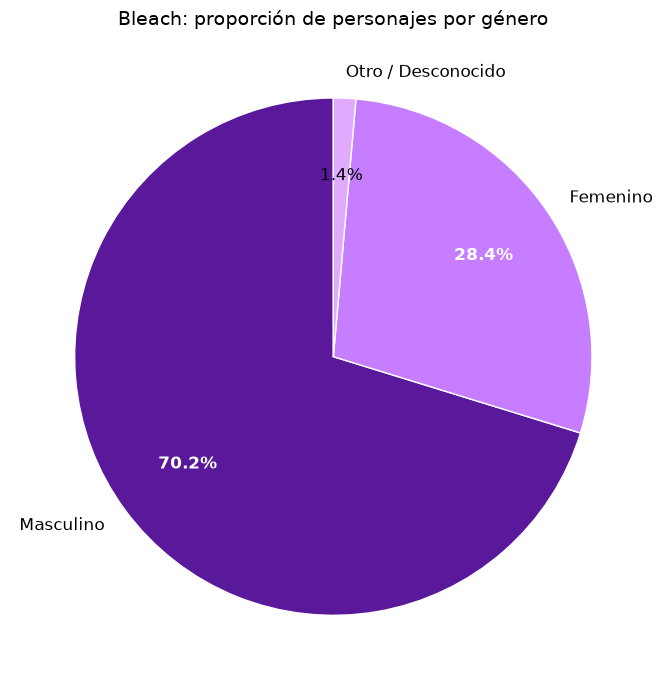

In [16]:
fig, ax = plt.subplots(figsize=(7, 7))
colores = ["#5A189A", "#C77DFF", "#E0AAFF"]  # morado oscuro, lila, lila claro
_, textos, porcentajes = ax.pie(
    genero.values, labels=genero.index, autopct="%1.1f%%", startangle=90,
    colors=colores[: len(genero)], pctdistance=0.7,
    wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 12},
)
for p in porcentajes[:2]:          # porcentajes en blanco sobre los morados
    p.set_color("white")
    p.set_fontweight("bold")
ax.set_title("Bleach: proporción de personajes por género", fontsize=14)
plt.tight_layout()
plt.show()

#### Gráfico 2 (barras) — Estatura promedio por categoría

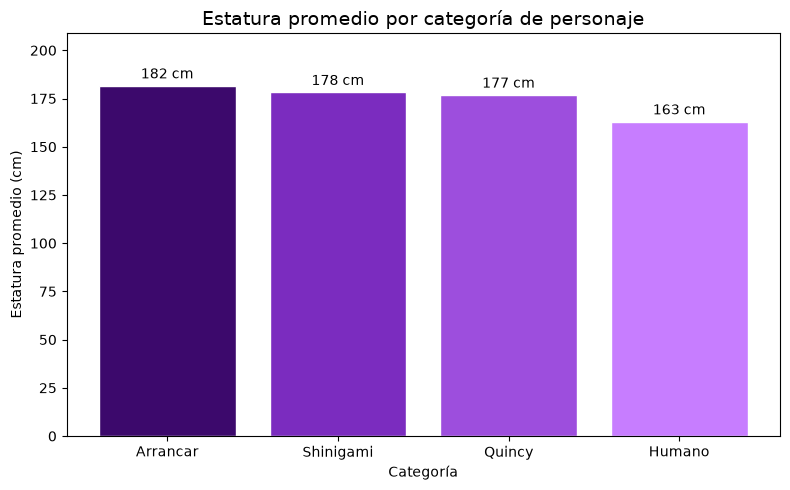

In [17]:
altura_cat = df.groupby("categoria")["altura_cm"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(altura_cat.index, altura_cat.values, color=["#3C096C", "#7B2CBF", "#9D4EDD", "#C77DFF"], edgecolor="white")
ax.bar_label(barras, fmt="%.0f cm", padding=3)
ax.set_title("Estatura promedio por categoría de personaje", fontsize=14)
ax.set_xlabel("Categoría")
ax.set_ylabel("Estatura promedio (cm)")
ax.set_ylim(0, altura_cat.max() * 1.15)
plt.tight_layout()
plt.show()

#### Gráfico 3 (histograma) — Capítulo del manga en que debutan los personajes

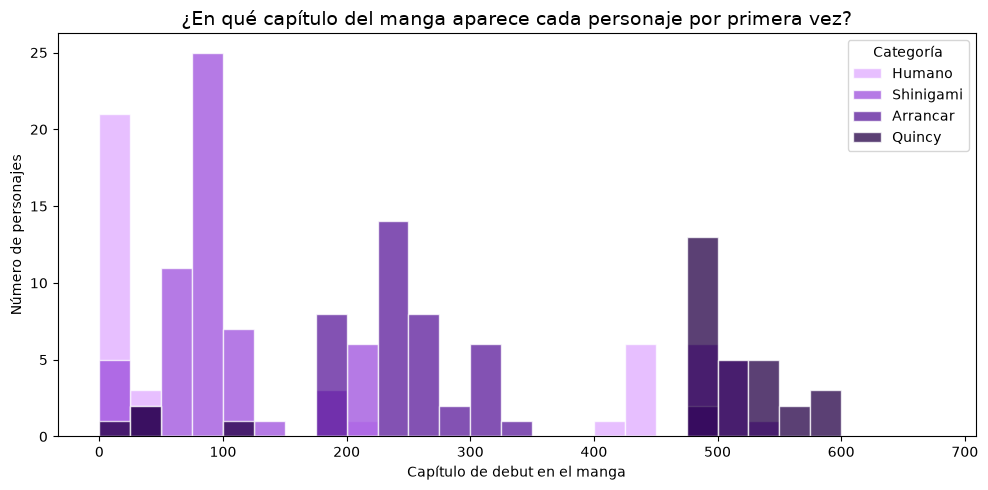

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
colores_hist = {"Humano": "#E0AAFF", "Shinigami": "#9D4EDD", "Arrancar": "#5A189A", "Quincy": "#240046"}
for cat, color in colores_hist.items():
    datos = df.loc[df["categoria"] == cat, "capitulo_debut"].dropna()
    ax.hist(datos, bins=range(0, 700, 25), alpha=0.75, label=cat, color=color, edgecolor="white")
ax.set_title("¿En qué capítulo del manga aparece cada personaje por primera vez?", fontsize=14)
ax.set_xlabel("Capítulo de debut en el manga")
ax.set_ylabel("Número de personajes")
ax.legend(title="Categoría")
plt.tight_layout()
plt.show()

### 8. Conclusiones
1. **Los Shinigami dominan el elenco:** son casi la mitad de los personajes de la API, seguidos por los Arrancar, los Humanos y los Quincy.
2. **El reparto es mayoritariamente masculino:** hay unos dos personajes y medio masculinos por cada personaje femenino.
3. **Los Arrancar son en promedio los más altos** y los Humanos los más bajos (muchos humanos son estudiantes o niños). Los dos extremos de estatura son Arrancar: Choe Neng Poww (el más alto) y Kukkapūro (el más bajo, que es un perro).
4. **El protagonismo se nota en los datos:** Ichigo Kurosaki es, por mucho, el personaje con más imágenes en la wiki, casi el doble que el segundo.
5. **El bankai es raro:** solo alrededor de 1 de cada 5 Shinigami tiene un bankai con nombre revelado, y muchos de ellos son capitanes o excapitanes.
6. **Los datos reflejan la estructura de la historia:** los Humanos debutan en los primeros capítulos, los Arrancar a mitad del manga y los Quincy en el arco final (*Thousand-Year Blood War*, alrededor del capítulo 480 en adelante).

In [19]:
client.close()